# Partial differential equations 2: Waves on a string

*Learning path: partial differential equations, part 2 of 3.* [Index](README.md) · Previous: [The heat equation](01-the-heat-equation.ipynb) · Next: [Laplace and Poisson](03-laplace-and-poisson.ipynb)

Pluck a guitar string and it vibrates at a clear pitch, with a mix of overtones that makes a guitar sound different
from a piano. Flick a long rope and a bump runs along it, bounces off the end and comes back upside down. Both are
described by the **wave equation**, which Jean le Rond d'Alembert wrote down in 1747 for a vibrating string. The same
equation describes sound in a pipe, light, ripples on a pond and the shaking of a building in an earthquake.

Where heat smooths wiggles away, waves carry them along. This lesson shows how a bump splits and travels, what
happens at the ends of the string, why a string has a pitch and overtones, and which speed limit a computer has to
obey to simulate waves at all.

**Who this is for.** Students who have done [the heat equation](01-the-heat-equation.ipynb).

**What you will be able to do afterwards:**

1. explain where the wave equation comes from and what the speed $c$ means;
2. solve it with `wave` and read the result as an animation and a space-time map;
3. explain d'Alembert's solution and the reflection at fixed and free ends;
4. find the pitch and the overtones of a string, and see them in a computed sound;
5. state and test the Courant condition $c\,\Delta t \le h$.

Plan about 60 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. Where the equation comes from

Think of the string as a row of beads of mass $m$ at distance $h$, joined by pieces of string under tension $\tau$.
Let $u_i$ be the sideways displacement of bead $i$. For small displacements the pull of a neighbour sideways is
$\tau$ times the slope of the string towards it, so Newton's law $m\,a = F$ gives

$$m\,\frac{d^2u_i}{dt^2} = \frac{\tau}{h}\,(u_{i-1} - 2u_i + u_{i+1}).$$

With mass per length $\rho = m/h$, letting $h \to 0$:

$$u_{tt} = c^2\, u_{xx}, \qquad c = \sqrt{\tau/\rho}.$$

Same right-hand side as the heat equation, but now it gives the **acceleration**, not the rate of change: a point that
lies below the average of its neighbours is pulled up, overshoots and swings back. The constant $c$ will turn out to
be the speed of the waves; a tighter or lighter string has faster waves.

Because the equation has a second time derivative, a solution needs two starting conditions: the shape $u(x, 0) = f(x)$
and the velocity $u_t(x, 0) = g(x)$. `wave(f, g, x, a, b, T)` solves it on $a \le x \le b$ up to time $T$, with the ends
held at 0. Here a bump is pushed out of a string at rest:

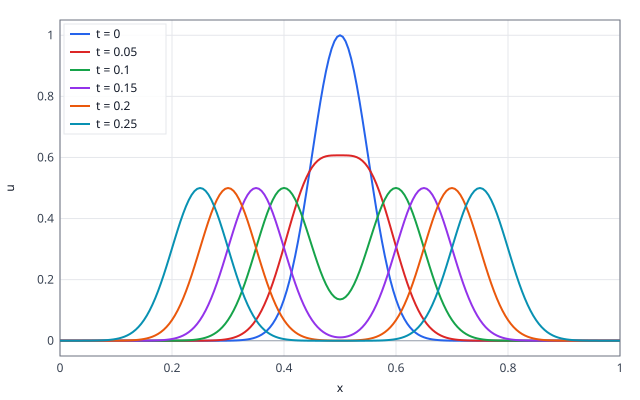

> pdeplot: u against x at 6 values of t.

In [1]:
s = wave(exp(-200*(x - 1/2)^2), 0, x, 0, 1, 1/4);
pdeplot(s, "lines")

The bump splits into two half-size bumps that run apart. In the animation you can watch them move:

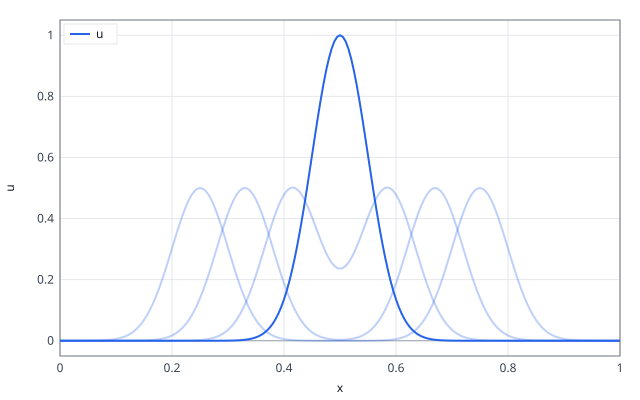

> pdeplot: the solution u(x) moving in time; press play or drag the slider (a still picture shows a few faint frames). pdeplot(s, "lines") draws snapshots side by side, pdeplot(s, "map") the whole history as colors.

In [2]:
pdeplot(s)

**Try this.** Read off from the snapshots how far each half-bump has travelled by $t = 1/4$. What is its speed? Now run
the same with `{c: 2}` as a last argument.

## 2. d'Alembert's solution

D'Alembert noticed that any shape moving to the right, $F(x - ct)$, solves the equation, and so does any shape moving
to the left, $G(x + ct)$: both have $u_{tt} = c^2 F''$ and $u_{xx} = F''$. For a string starting at rest,

$$u(x, t) = \tfrac12 f(x - ct) + \tfrac12 f(x + ct),$$

two half copies of the starting shape, one running each way. Check the computed peak at $t = 1/4$ at $x = 1/4$ (grid point
51 of 201):

In [3]:
U = s.u;
final = U(end);
eval(final(51), 4)
eval(1/2*exp(-200*(1/4 - 1/2)^2) + 1/2*exp(-200*(1/4 + 1/4 - 1/2)^2), 4)

0.5000

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.5000

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The space-time map shows the two halves as two straight tracks, $x = 1/2 \pm ct$: information travels at speed $c$
along these lines, the **characteristics**. Run longer to see what happens at the ends. At the left end the string is
held; at the right end it is `"free"` (a ring that slides on a pole without friction, so the slope there is 0):

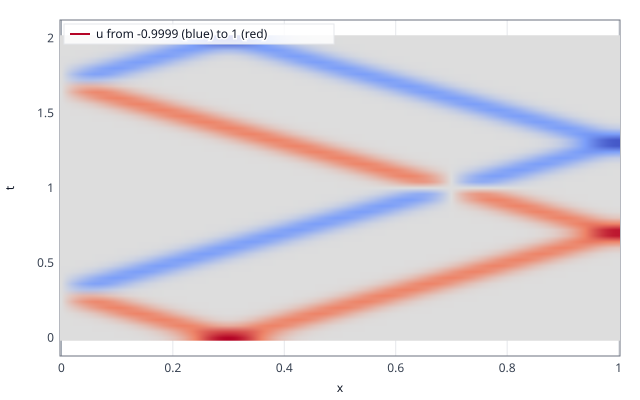

> pdeplot: the whole history as colors, x across and time t upward; blue is low, red is high.

In [4]:
s = wave(exp(-200*(x - 0.3)^2), 0, x, 0, 1, 2, {right: "free"});
pdeplot(s, "map")

Red is up, blue is down. A bump that hits the **fixed** end comes back **upside down**; one that hits the **free** end
comes back the **same way up**. D'Alembert's trick explains both: a fixed end acts as if an upside-down mirror image
were coming the other way, cancelling the displacement at the end; a free end acts as if an upright mirror image were
coming, so the slopes cancel.

**Try this.** Make both ends free, `{left: "free", right: "free"}`. Where is the bump at $t = 2$, and which way up?

## 3. Standing waves, pitch and overtones

A string held at both ends cannot carry any wave forever in one direction: it bounces back and forth. Some shapes simply
swing up and down in place, the **standing waves**

$$u = \sin(m\pi x)\cos(m\pi c\, t), \qquad m = 1, 2, 3, \dots$$

The $m$-th one repeats after time $2/(mc)$, so it has **frequency** $mc/2$ for a string of length 1, or $mc/(2L)$ for
length $L$. The first, $c/(2L)$, is the pitch you hear; the others are the **overtones** or harmonics, at 2, 3, 4,
... times the pitch. That whole-number pattern is why a string sounds musical (a drum, whose overtones are not whole
multiples, sounds less so).

A plucked string starts as a tent with its peak where it was plucked. Pluck at $1/5$ of its length, with height
$1/10$, and listen at a point near the bridge, $x = 0.1$ (grid point 21), for 16 time units:

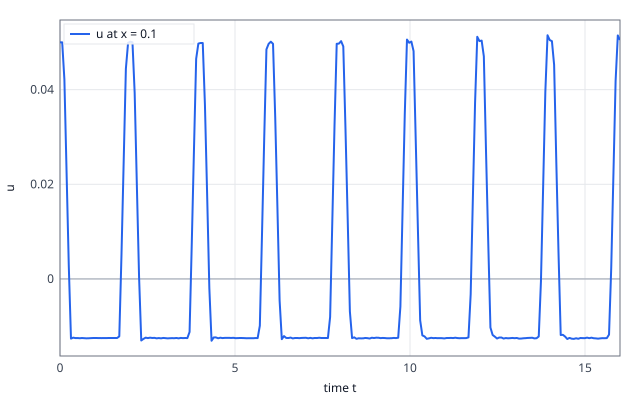

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = 1/5;
tent = (x/p + (1 - x)/(1 - p) - abs(x/p - (1 - x)/(1 - p)))/20;
s = wave(tent, 0, x, 0, 1, 16, {frames: 255});
U = s.u;
sound = column(U, 21);
labels(legend(plot(s.t, sound'), "u at x = 0.1"), "time t", "u")

The signal repeats with period 2: the pitch is $c/2 = 1/2$. Its **spectrum**, the size of each frequency in it,
comes from the fast Fourier transform. The 256 samples are $16/255$ apart, so entry $k$ of the transform is the
frequency $k \cdot 255/(16 \cdot 256)$:

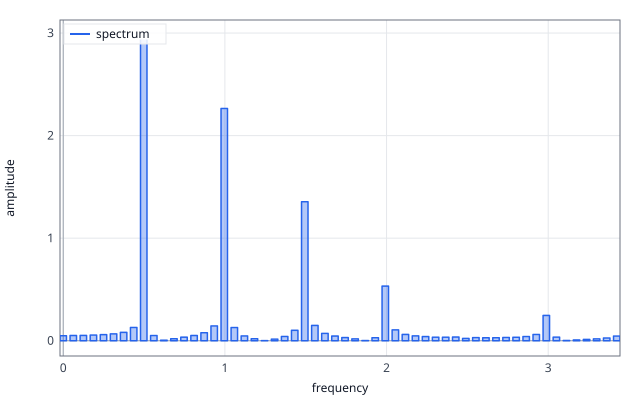

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
F = abs(fft(sound));
amp = zeros(1, 56);
fr = zeros(1, 56);
for k = 1:56
  amp(k) = F(k);
  fr(k) = (k - 1)*255/(16*256);
end
labels(legend(bar(fr, amp, 0.04), "spectrum"), "frequency", "amplitude")

Peaks at $0.5$, $1$, $1.5$, $2$, $3$, ... are the pitch and its harmonics. The fifth harmonic, at $2.5$, is missing:
the string was plucked at $1/5$ of its length, exactly where $\sin(5\pi x)$ is zero, so that overtone was never
excited. Guitarists use this: plucking near the middle gives a soft, round sound (few high overtones); plucking near
the bridge gives a bright, twangy one.

The size of each harmonic follows from Fourier's sine series of the tent:
$b_m = \dfrac{2h\,\sin(m\pi p)}{m^2\pi^2\,p\,(1 - p)}$, with $h = 1/10$:

In [7]:
b = zeros(1, 8);
for m = 1:8
  b(m) = 2*(1/10)*sin(m*pi*p)/(m^2*pi^2*p*(1 - p));
end
eval(b, 3)

[0.0744, 0.0301, 0.0134, 0.00465, 0.000, -0.00207, -0.00246, -0.00188]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** Pluck in the middle ($p = 1/2$). Which harmonics are missing now? Predict with the formula for $b_m$, then
check with the spectrum (listen at $x = 0.1$ again).

## 4. The speed limit: the Courant condition

`wave` uses the **leapfrog** scheme: replace both second derivatives by second differences,

$$u_i^{\text{next}} = 2u_i - u_i^{\text{prev}} + \Big(\frac{c\,\Delta t}{h}\Big)^2 (u_{i-1} - 2u_i + u_{i+1}).$$

The number $C = c\,\Delta t/h$ is the **Courant number**. In 1928 Richard Courant, Kurt Friedrichs and Hans Lewy showed
that the scheme only works when $C \le 1$: in one time step the true wave moves a distance $c\,\Delta t$, and the scheme,
which only looks at the neighbours, must be able to reach that far, $h \ge c\,\Delta t$. Try it by hand with 30
pieces and a matrix step, as in lesson 1, once just below the limit and once just above:

In [8]:
n = 30;
xs = linspace(1/n, 1 - 1/n, n - 1);
u0 = exp(-100*(xs - 1/2).^2);
for courant = [0.9 1.1]
  q = courant^2;
  C = zeros(n - 1, n - 1);
  for i = 1:n - 1
    C(i, i) = 2 - 2*q;
    if i > 1
      C(i, i - 1) = q;
    end
    if i < n - 1
      C(i, i + 1) = q;
    end
  end
  prev = u0;
  u = u0;
  for step = 1:60
    nxt = u*C - prev;
    prev = u;
    u = nxt;
  end
  print(courant, eval(max(abs(u)), 3))
end

0.9 0.506
1.1 8.69e13

With $C = 0.9$ the largest displacement after 60 steps is about the size of the half-bumps; with $C = 1.1$ it is
around $10^{14}$. The same fastest zigzag as in the heat equation is to blame. `wave` always picks $\Delta t$ so that
$C \le 0.9$; its note gives the value.

**Try this.** Run the loop with Courant numbers `[1 1.01 1.05]`. How quickly does the blow-up set in just above the
limit?

## 5. Damping

A real string loses energy to the air and the guitar body, and its sound fades. Adding a friction term gives the
**damped wave equation** $u_{tt} = c^2 u_{xx} - \gamma\, u_t$. The `damping` option sets $\gamma$:

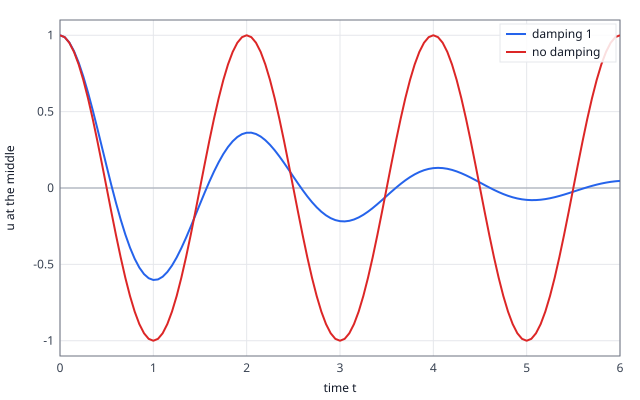

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
s = wave(sin(pi*x), 0, x, 0, 1, 6, {damping: 1, frames: 120});
U = s.u;
p = legend(plot(s.t, column(U, 101)'), "damping 1");
s2 = wave(sin(pi*x), 0, x, 0, 1, 6, {frames: 120});
U2 = s2.u;
p = show(p, legend(plot(s2.t, column(U2, 101)'), "no damping"));
labels(p, "time t", "u at the middle")

For the first standing wave the middle of the string behaves like a damped spring: it oscillates inside the envelope
$e^{-\gamma t/2}$, slightly slower than without damping.

**Try this.** With very strong damping the string no longer swings but creeps back to rest. For the first standing
wave this happens from $\gamma = 2\pi$ (critical damping, as for the spring
$\ddot u + \gamma \dot u + \pi^2 u = 0$). Try $\gamma = 2\pi$ and $\gamma = 20$.

## Summary

* The wave equation $u_{tt} = c^2 u_{xx}$ is Newton's law for a string; $c = \sqrt{\tau/\rho}$ is the wave speed.
* d'Alembert: $u = F(x - ct) + G(x + ct)$; a bump at rest splits into two halves travelling at speed $c$.
* At a fixed end a wave reflects upside down, at a free end the same way up.
* A string of length $L$ vibrates at $c/(2L)$ and its whole multiples; where it is plucked decides the overtones.
* The leapfrog scheme needs the Courant condition $c\Delta t \le h$; `wave` keeps it below 0.9.

Next: [Laplace and Poisson](03-laplace-and-poisson.ipynb), the equations of things that have stopped changing.

## Exercises

1. **Tuning.** A guitar's top string is 0.65 m long and tuned to 330 Hz. What is the wave speed $c$ on it? If the
   player presses it halfway, which note (frequency) sounds?
2. **Push, not pluck.** Hit a string at rest with a hammer: start from `f = 0` and a velocity bump,
   `wave(0, exp(-200*(x - 1/2)^2), x, 0, 1, 1/4)`. Describe the shape after a while. (A piano does this.)
3. **A wave that does not split.** Find a starting velocity $g$ that sends the bump $f = e^{-200(x - 0.3)^2}$ only
   to the right. Hint: for $u = f(x - ct)$, $u_t = -c f'$.
4. **Echo time.** A rope 20 m long carries waves at 5 m/s, and is fixed at the far end. You flick your end. When does
   the echo come back, and which way up?
5. **Courant in practice.** With $c = 340$ m/s (sound) and a grid spacing of 1 cm, what is the largest time step the
   leapfrog scheme can use? How many steps does one second of sound take?

## Hints and answers

* **Section 1, Try this.** Each half travels $1/4$ in time $1/4$: speed 1. With `c: 2` they travel twice as far,
  reaching the ends at $t = 1/4$.
* **Section 2, Try this.** With two free ends there is no flip: the halves bounce off both ends the same way up, and at
  $t = 2$ the bump is back at $x = 0.3$, upright. (Each half travels 2 in time 2: one full round trip.)
* **Section 3, Try this.** $\sin(m\pi/2) = 0$ for even $m$, so all even harmonics (frequencies 1, 2, 3, ...) are missing;
  only 0.5, 1.5, 2.5, ... remain.
* **Section 4, Try this.** At $C = 1$ the scheme stays bounded (it is exact for this equation, a lucky special case);
  at $1.01$ the growth is slow (a factor of about 1.3 per step at the worst zigzag) but still exponential, and after
  a few hundred steps it would dominate; at $1.05$ it is visible within 60 steps.
* **Section 5, Try this.** At $\gamma = 2\pi$ the middle point creeps to 0 without crossing it; at $\gamma = 20$ it
  creeps even more slowly (overdamped).
* **Exercise 1.** $c = 2Lf = 2 \cdot 0.65 \cdot 330 \approx 429$ m/s; half the length doubles the frequency, 660 Hz, an
  octave higher.
* **Exercise 2.** Two flat-topped plateaus spreading apart: the velocity bump turns into a step-like displacement
  $\frac{1}{2c}\int_{x - ct}^{x + ct} g$.
* **Exercise 3.** $g = -f'(x) = 400(x - 0.3)\,e^{-200(x - 0.3)^2}$ (with $c = 1$).
* **Exercise 4.** After $2 \cdot 20/5 = 8$ s, upside down.
* **Exercise 5.** $\Delta t \le h/c \approx 2.9 \cdot 10^{-5}$ s, so at least 34 000 steps per second.

## Sources

1. J. le Rond d'Alembert, "Recherches sur la courbe que forme une corde tenduë mise en vibration", *Histoire de
   l'Académie Royale des Sciences et Belles-Lettres de Berlin* 3 (1747), 214–219.
2. R. Courant, K. Friedrichs and H. Lewy, "Über die partiellen Differenzengleichungen der mathematischen Physik",
   *Mathematische Annalen* 100 (1928), 32–74.
3. W. A. Strauss, *Partial Differential Equations: An Introduction*, 2nd ed., Wiley (2008), chapters 2 and 4.
4. N. H. Fletcher and T. D. Rossing, *The Physics of Musical Instruments*, 2nd ed., Springer (1998), chapter 2
   (vibrating strings).